
#### SHAP XAI means SHapley Additive exPlanations. 
    
    It is a popular Explainable AI (XAI) technique used to understand why a machine-learning model made a particular prediction.

 SHAP answers: Which features pushed the prediction toward diabetes, and which features pushed it away?
     


    * The size tells us how strongly the feature affected the prediction.
    

### Example

In [1]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

data = pd.read_csv("data/diabetes.csv")
data

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [2]:

X = data.drop("Outcome", axis=1)
y = data["Outcome"]

X_train, X_test, y_train, y_test = train_test_split( X,  y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier( n_estimators=100, random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.7597402597402597


In [3]:
import shap

explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(X_test)

print("X_test shape:", X_test.shape)
print("SHAP shape:", shap_values.shape)

X_test shape: (154, 8)
SHAP shape: (154, 8, 2)


In [4]:
if len(shap_values.shape) == 3:
   
    shap_values_class1 = shap_values[:, :, 1]
else:
    shap_values_class1 = shap_values

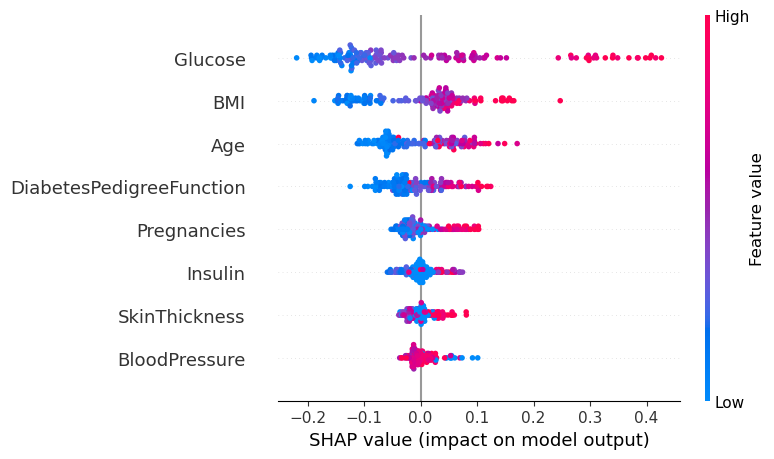

In [6]:

shap.summary_plot(shap_values_class1, X_test)


Y-axis = Feature importance

         The features are arranged from most important at the top to least important at the bottom.
    

If Glucose is at the top:
    
        Glucose has the greatest overall influence on the model's diabetes predictions.


X-axis = SHAP value

         The horizontal axis represents the SHAP value.

Negative SHAP value

                    A point on the left means:

                                This feature pushed the prediction away from diabetes (class 1).

Positive SHAP value

                    A point on the right means:

                                This feature pushed the prediction toward diabetes (class 1).

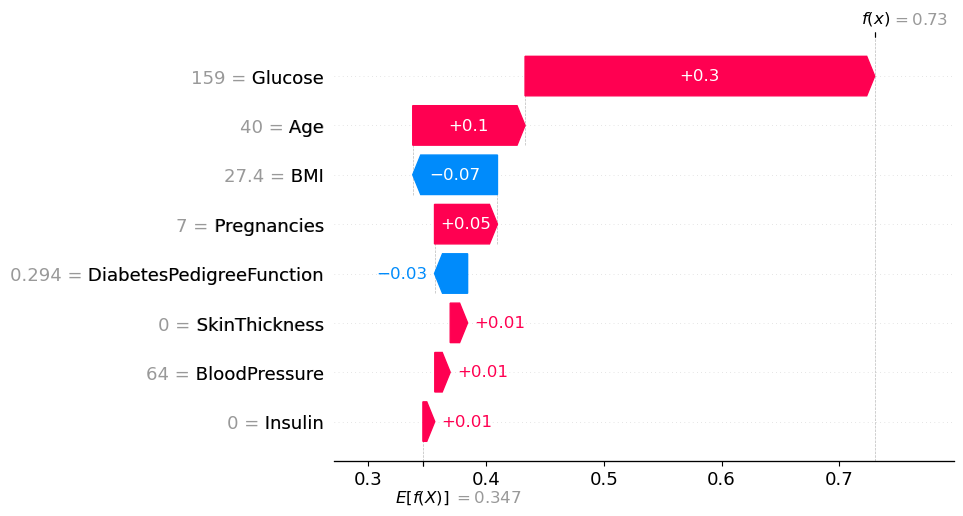

In [7]:
patient_index = 0

shap.waterfall_plot(
    shap.Explanation(
        values=shap_values_class1[patient_index],
        base_values=explainer.expected_value[1],
        data=X_test.iloc[patient_index],
        feature_names=X_test.columns
    )
)

| Feature                  | Patient value | SHAP contribution | Effect             |
| ------------------------ | ------------: | ----------------: | ------------------ |
| Glucose                  |           159 |         **+0.30** | Toward diabetes    |
| Age                      |            40 |         **+0.10** | Toward diabetes    |
| BMI                      |          27.4 |         **−0.07** | Away from diabetes |
| Pregnancies              |             7 |         **+0.05** | Toward diabetes    |
| DiabetesPedigreeFunction |         0.294 |         **−0.03** | Away from diabetes |
| SkinThickness            |             0 |         **+0.01** | Toward diabetes    |
| BloodPressure            |            64 |         **+0.01** | Toward diabetes    |
| Insulin                  |             0 |         **+0.01** | Toward diabetes    |


At the top:

f(x) = 0.73

So the model's final output for class 1 (diabetes) is approximately: 0.73

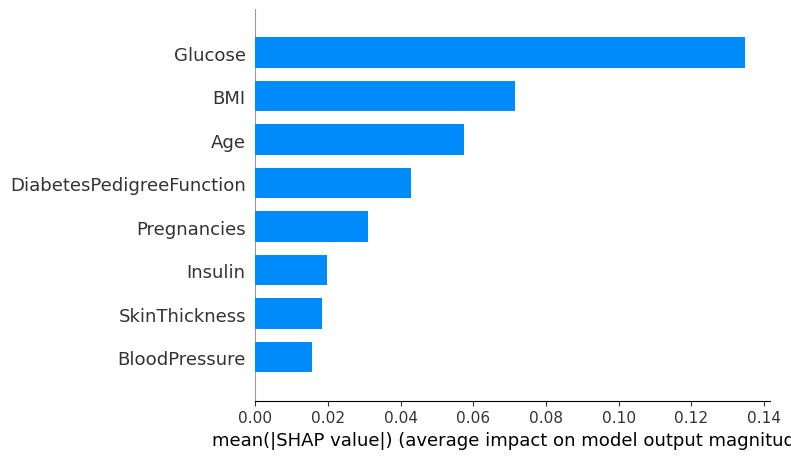

In [8]:
shap.summary_plot(
    shap_values_class1,
    X_test,
    plot_type="bar"
)

#### Glucose is the most important feature for the model.

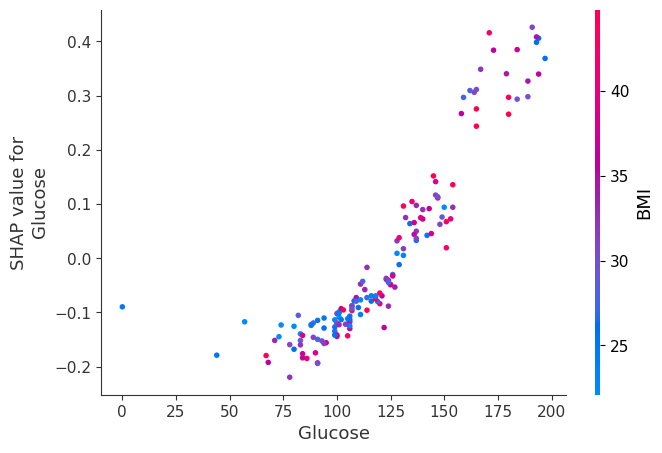

In [10]:
shap.dependence_plot(
    "Glucose",
    shap_values_class1,
    X_test
)

In [5]:
shap_values_class1

array([[ 5.34180946e-02,  2.96691035e-01,  1.30969213e-02, ...,
        -7.19050211e-02, -2.80893059e-02,  9.53209491e-02],
       [ 6.70887256e-02, -1.92159860e-01,  1.98462778e-02, ...,
        -8.84683197e-04, -4.53887877e-02,  5.74372221e-02],
       [-4.88343611e-02, -1.27833035e-01, -1.37000893e-02, ...,
         2.74546249e-02, -2.94517421e-02, -1.12159447e-01],
       ...,
       [-3.96937840e-02, -1.05356498e-01, -3.70923357e-02, ...,
        -3.86063966e-02,  1.07841839e-01, -5.14554800e-02],
       [-3.29631259e-02,  3.84870392e-01,  8.20026626e-05, ...,
         3.86556135e-02, -4.62589599e-02,  2.65822634e-02],
       [-2.43032171e-02, -1.51581060e-01, -6.47975555e-03, ...,
         2.18730455e-02, -2.35251721e-02, -6.01238864e-02]],
      shape=(154, 8))